# Phase 6 — Model Development & Comparison

## Objective

This notebook compares the Phase 5 `SGDClassifier` baseline with Random Forest, Gradient Boosting, and XGBoost using the same processed training data, fixed test data, target, and evaluation metrics.

No SMOTE, oversampling, undersampling, hyperparameter tuning, threshold optimization, SHAP, API, database, or dashboard work is performed.

> **Metric definition:** PR-AUC is reported as Average Precision (`sklearn.metrics.average_precision_score`) via `src.fraud.metrics.pr_auc`. The stored metric outputs were refreshed from saved test probabilities under scikit-learn 1.9.0; training times and feature importances remain from the historical Phase 6 run.


## 1. Load Processed Data and Baseline

In [1]:
import sys
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import sparse

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    precision_recall_curve, confusion_matrix, roc_curve
)
from xgboost import XGBClassifier

project = Path.cwd().resolve()
project = project.parent if project.name == "notebooks" else project
sys.path.insert(0, str(project))
from src.fraud.metrics import pr_auc as compute_pr_auc

processed = project / "data" / "processed"
models_folder = project / "models"
results_folder = project / "results"
models_folder.mkdir(exist_ok=True)
results_folder.mkdir(exist_ok=True)

X_train = sparse.load_npz(processed / "X_train_processed.npz")
X_test = sparse.load_npz(processed / "X_test_processed.npz")
y_train = pd.read_csv(processed / "y_train.csv")["isFraud"]
y_test = pd.read_csv(processed / "y_test.csv")["isFraud"]
baseline_model = joblib.load(models_folder / "baseline_sgd.pkl")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Baseline loaded; it will not be retrained.")

X_train: (472432, 495)
X_test: (118108, 495)
Baseline loaded; it will not be retrained.


## 2. Validate Data

In [2]:
assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
assert X_train.shape[1] == X_test.shape[1]
for name, matrix in [("X_train", X_train), ("X_test", X_test)]:
    values = matrix.data if sparse.issparse(matrix) else matrix
    assert np.isfinite(values).all()
print("Train samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])
print("Features:", X_train.shape[1])
print("NaN/Inf validation: passed")
print("Train/Test fixed for every model: yes")

Train samples: 472432
Test samples: 118108
Features: 495
NaN/Inf validation: passed
Train/Test fixed for every model: yes


## 3. Common Evaluation Function

In [3]:
def evaluate_model(model, X_test, y_test):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    precision = precision_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)
    f1 = f1_score(y_test, pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, proba)
    pr_auc = compute_pr_auc(y_test, proba)
    return {
        "Precision": precision, "Recall": recall, "F1": f1,
        "ROC-AUC": roc_auc, "PR-AUC": pr_auc,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Prediction Count": len(pred), "Probability Count": len(proba),
        "Probability Min": proba.min(), "Probability Max": proba.max(),
        "pred": pred, "proba": proba
    }

results = {}
times = {}
print("All models will use the same evaluate_model function and fixed X_test/y_test.")

All models will use the same evaluate_model function and fixed X_test/y_test.


## 4. Evaluate Phase 5 SGD Baseline

In [4]:
start = time.time()
results["SGD"] = evaluate_model(baseline_model, X_test, y_test)
times["SGD"] = time.time() - start
print({k: results["SGD"][k] for k in ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "TN", "FP", "FN", "TP"]})
print("Baseline evaluation time (seconds):", times["SGD"])

{'Precision': 0.22609570866501968, 'Recall': 0.597870796031938, 'F1': 0.3281104766963219, 'ROC-AUC': 0.8606540395418893, 'PR-AUC': 0.286753034303506, 'TN': np.int64(105517), 'FP': np.int64(8458), 'FN': np.int64(1662), 'TP': np.int64(2471)}
Baseline evaluation time (seconds): 1.0769002437591553


## 5. Random Forest

In [5]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
print("Configuration: 50 trees, class_weight='balanced', random_state=42.")
print("This is a simplified configuration for the large dataset; no tuning is performed.")
start = time.time()
rf_model.fit(X_train, y_train)
times["Random Forest"] = time.time() - start
results["Random Forest"] = evaluate_model(rf_model, X_test, y_test)
print("Training time (seconds):", times["Random Forest"])
print({k: results["Random Forest"][k] for k in ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "TN", "FP", "FN", "TP"]})

Configuration: 50 trees, class_weight='balanced', random_state=42.
This is a simplified configuration for the large dataset; no tuning is performed.


Training time (seconds): 1045.306457042694
{'Precision': 0.8682564503518374, 'Recall': 0.5373820469392693, 'F1': 0.6638768494993275, 'ROC-AUC': 0.94051273867316, 'PR-AUC': 0.7224630422250053, 'TN': np.int64(113638), 'FP': np.int64(337), 'FN': np.int64(1912), 'TP': np.int64(2221)}


## 6. Gradient Boosting

In [6]:
# GradientBoostingClassifier requires a dense matrix. This simplified model is used because the dataset is large.
X_train_dense = X_train.toarray().astype(np.float32)
X_test_dense = X_test.toarray().astype(np.float32)
gb_model = GradientBoostingClassifier(
    n_estimators=10,
    learning_rate=0.1,
    max_depth=2,
    random_state=42
)
print("Configuration: 10 estimators, max_depth=2, learning_rate=0.1.")
print("A simplified configuration is documented because dense Gradient Boosting is computationally expensive here.")
start = time.time()
gb_model.fit(X_train_dense, y_train)
times["Gradient Boosting"] = time.time() - start
results["Gradient Boosting"] = evaluate_model(gb_model, X_test_dense, y_test)
print("Training time (seconds):", times["Gradient Boosting"])
print({k: results["Gradient Boosting"][k] for k in ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "TN", "FP", "FN", "TP"]})

Configuration: 10 estimators, max_depth=2, learning_rate=0.1.
A simplified configuration is documented because dense Gradient Boosting is computationally expensive here.


Training time (seconds): 340.59073877334595
{'Precision': 0.875, 'Recall': 0.1270263730946044, 'F1': 0.22184660891612085, 'ROC-AUC': 0.7891038170563359, 'PR-AUC': 0.34313683058794475, 'TN': np.int64(113900), 'FP': np.int64(75), 'FN': np.int64(3608), 'TP': np.int64(525)}


## 7. XGBoost

In [7]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = XGBClassifier(
    n_estimators=50,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1,
    tree_method="hist"
)
print("Training scale_pos_weight:", scale_pos_weight)
print("Configuration: 50 estimators, max_depth=6, hist tree method.")
print("scale_pos_weight is calculated from y_train only to reflect class imbalance without resampling.")
start = time.time()
xgb_model.fit(X_train, y_train)
times["XGBoost"] = time.time() - start
results["XGBoost"] = evaluate_model(xgb_model, X_test, y_test)
print("Training time (seconds):", times["XGBoost"])
print({k: results["XGBoost"][k] for k in ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "TN", "FP", "FN", "TP"]})

Training scale_pos_weight: 27.580278281911674
Configuration: 50 estimators, max_depth=6, hist tree method.
scale_pos_weight is calculated from y_train only to reflect class imbalance without resampling.


Training time (seconds): 47.750301361083984
{'Precision': 0.19025644021262925, 'Recall': 0.7880474231792887, 'F1': 0.3065123282514587, 'ROC-AUC': 0.909752556833817, 'PR-AUC': 0.5734568342621466, 'TN': np.int64(100113), 'FP': np.int64(13862), 'FN': np.int64(876), 'TP': np.int64(3257)}


## 8. Validate Predictions and Probabilities

In [8]:
for name, result in results.items():
    assert result["Prediction Count"] == len(y_test)
    assert result["Probability Count"] == len(y_test)
    assert 0 <= result["Probability Min"] <= 1
    assert 0 <= result["Probability Max"] <= 1
    print(name, "prediction/probability checks passed")

SGD prediction/probability checks passed
Random Forest prediction/probability checks passed
Gradient Boosting prediction/probability checks passed
XGBoost prediction/probability checks passed


## 9. Model Comparison Table

In [9]:
comparison_rows = []
for name, result in results.items():
    comparison_rows.append({"Model": name, **{k: result[k] for k in ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "TN", "FP", "FN", "TP"]}, "Training Time (seconds)": times[name]})
comparison = pd.DataFrame(comparison_rows)
display(comparison.sort_values(["PR-AUC", "F1"], ascending=False))

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP,Training Time (seconds)
1,Random Forest,0.868256,0.537382,0.663877,0.940513,0.722463,113638,337,1912,2221,1045.306457
3,XGBoost,0.190256,0.788047,0.306512,0.909753,0.573457,100113,13862,876,3257,47.750301
2,Gradient Boosting,0.875000,0.127026,0.221847,0.789104,0.343137,113900,75,3608,525,340.590739
0,SGD,0.226096,0.597871,0.328110,0.860654,0.286753,105517,8458,1662,2471,1.076900


## 10. ROC and Precision-Recall Curve Comparison

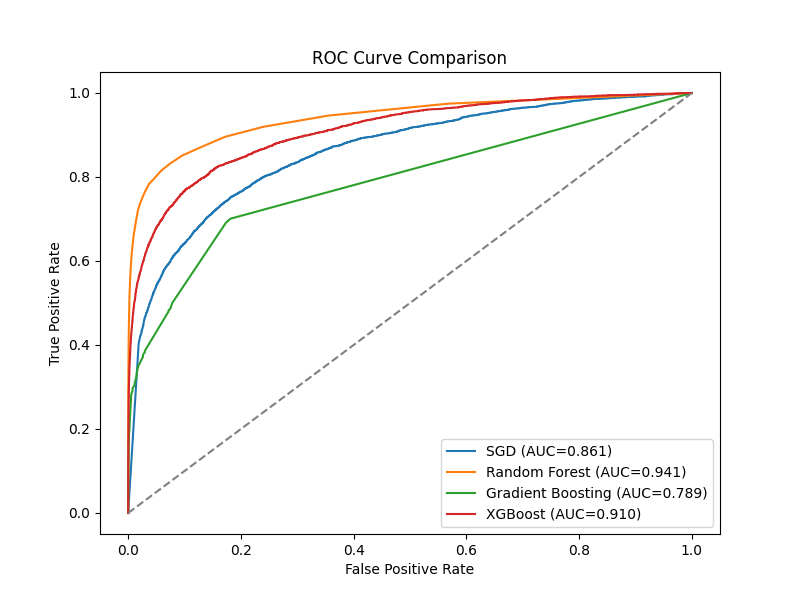

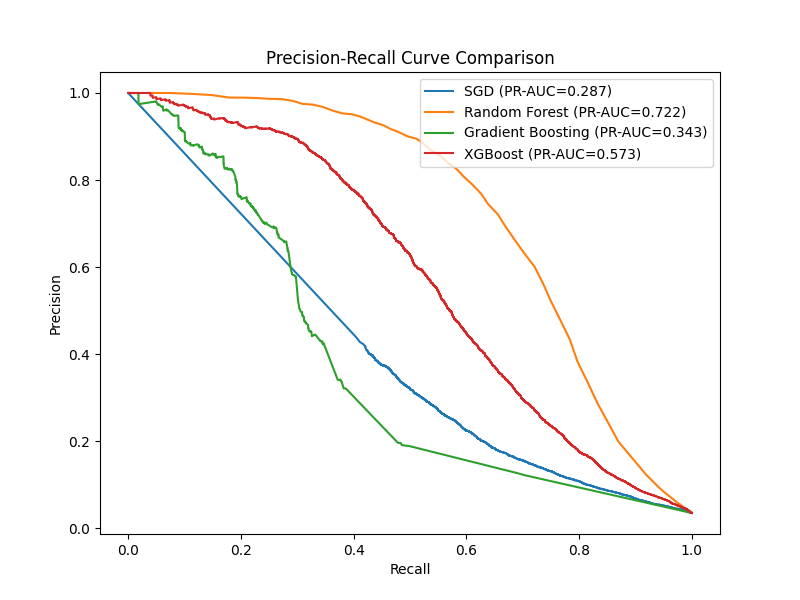

In [10]:
plt.figure(figsize=(8, 6))
for name, result in results.items():
    fpr, tpr, _ = roc_curve(y_test, result["proba"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={result['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

plt.figure(figsize=(8, 6))
for name, result in results.items():
    p, r, _ = precision_recall_curve(y_test, result["proba"])
    plt.plot(r, p, label=f"{name} (PR-AUC={result['PR-AUC']:.3f})")
plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

**Interpretation:** PR-AUC, recall, precision, F1, and false-negative counts are considered together. The highest single metric is not automatically the best production choice.

## 11. Confusion Matrix and Error Comparison

In [11]:
error_table = comparison[["Model", "FP", "FN", "TP", "TN"]]
display(error_table)
for name, result in results.items():
    print(name, "false positives:", result["FP"], "false negatives:", result["FN"])
print("False negative: fraudulent transaction missed.")
print("False positive: legitimate transaction flagged.")

,Model,FP,FN,TP,TN
0,SGD,8458,1662,2471,105517
1,Random Forest,337,1912,2221,113638
2,Gradient Boosting,75,3608,525,113900
3,XGBoost,13862,876,3257,100113


SGD false positives: 8458 false negatives: 1662
Random Forest false positives: 337 false negatives: 1912
Gradient Boosting false positives: 75 false negatives: 3608
XGBoost false positives: 13862 false negatives: 876
False negative: fraudulent transaction missed.
False positive: legitimate transaction flagged.


## 12. Feature Importance for Tree Models

In [12]:
importance_rows = []
for model_name, model in [("Random Forest", rf_model), ("XGBoost", xgb_model)]:
    importance = model.feature_importances_
    top_indices = np.argsort(importance)[-10:][::-1]
    for rank, index in enumerate(top_indices, 1):
        importance_rows.append({"Model": model_name, "Rank": rank, "Feature": f"processed_feature_{index}", "Importance": importance[index]})
importance_table = pd.DataFrame(importance_rows)
display(importance_table)
print("Feature names are represented by processed column positions because the saved sparse matrix does not carry the original feature-name list.")
print("Importance indicates contribution to model predictions; it does not prove causation.")

,Model,Rank,Feature,Importance
0,Random Forest,1,processed_feature_1,0.029250
1,Random Forest,2,processed_feature_0,0.027633
2,Random Forest,3,processed_feature_22,0.025836
3,Random Forest,4,processed_feature_2,0.023774
4,Random Forest,5,processed_feature_3,0.020804
5,Random Forest,6,processed_feature_23,0.019740
6,Random Forest,7,processed_feature_6,0.017811
7,Random Forest,8,processed_feature_303,0.014416
8,Random Forest,9,processed_feature_257,0.013073
9,Random Forest,10,processed_feature_489,0.013020


Feature names are represented by processed column positions because the saved sparse matrix does not carry the original feature-name list.
Importance indicates contribution to model predictions; it does not prove causation.


## 13. Model Ranking and Candidate Selection

In [13]:
ranking = comparison.sort_values(["PR-AUC", "F1", "Recall", "Precision"], ascending=False).reset_index(drop=True)
ranking["Rank"] = np.arange(1, len(ranking) + 1)
display(ranking[["Rank", "Model", "PR-AUC", "F1", "Recall", "Precision", "FP", "FN", "Training Time (seconds)"]])
best_candidate = ranking.loc[0, "Model"]
best_row = ranking.loc[0]
print("Selected Model:", best_candidate)
print("Reason: strongest primary PR-AUC with secondary consideration of F1, recall, precision, errors, and training cost.")
print("Main Strength: actual fraud-detection ranking/classification performance shown in the comparison table.")
print("Main Weakness: computational cost and model complexity must be considered for deployment.")

,Rank,Model,PR-AUC,F1,Recall,Precision,FP,FN,Training Time (seconds)
0,1,Random Forest,0.722463,0.663877,0.537382,0.868256,337,1912,1045.306457
1,2,XGBoost,0.573457,0.306512,0.788047,0.190256,13862,876,47.750301
2,3,Gradient Boosting,0.343137,0.221847,0.127026,0.875000,75,3608,340.590739
3,4,SGD,0.286753,0.328110,0.597871,0.226096,8458,1662,1.076900


Selected Model: Random Forest
Reason: strongest primary PR-AUC with secondary consideration of F1, recall, precision, errors, and training cost.
Main Strength: actual fraud-detection ranking/classification performance shown in the comparison table.
Main Weakness: computational cost and model complexity must be considered for deployment.


## 14. Save Models and Results

In [14]:
joblib.dump(rf_model, models_folder / "random_forest.pkl")
joblib.dump(gb_model, models_folder / "gradient_boosting.pkl")
joblib.dump(xgb_model, models_folder / "xgboost.pkl")
comparison.to_csv(results_folder / "model_comparison.csv", index=False)
print("Saved baseline_sgd.pkl, random_forest.pkl, gradient_boosting.pkl, xgboost.pkl")
print("Saved:", results_folder / "model_comparison.csv")
for path in [models_folder / "baseline_sgd.pkl", models_folder / "random_forest.pkl", models_folder / "gradient_boosting.pkl", models_folder / "xgboost.pkl", results_folder / "model_comparison.csv"]:
    print(path.name, path.exists(), path.stat().st_size if path.exists() else 0, "bytes")

Saved baseline_sgd.pkl, random_forest.pkl, gradient_boosting.pkl, xgboost.pkl
Saved: C:\Users\HP\Desktop\fraud-detection-system\results\model_comparison.csv
baseline_sgd.pkl True 5078 bytes
random_forest.pkl True 164719529 bytes
gradient_boosting.pkl True 20600 bytes
xgboost.pkl True 218170 bytes
model_comparison.csv True 651 bytes


## Phase 6 — Final Model Comparison Report

In [15]:
print("PHASE 6 — FINAL MODEL COMPARISON REPORT")
print("=" * 50)
print("Models Evaluated: SGDClassifier, Random Forest, Gradient Boosting, XGBoost")
print("\nComplete Comparison:")
display(comparison.sort_values(["PR-AUC", "F1"], ascending=False))
for metric in ["PR-AUC", "Recall", "Precision", "F1"]:
    row = comparison.loc[comparison[metric].idxmax()]
    print(f"Best {metric}: {row['Model']} = {row[metric]}")
print("\nSelected Candidate:", best_candidate)
print("Reason: ranked using PR-AUC first, then F1, Recall, Precision, error counts, and training cost.")
print("\nTraining times (seconds):")
print(times)
print("\nFeature importance summary:")
display(importance_table.groupby("Model").head(5))
print("\nModel limitations: all results depend on Phase 4 preprocessing; advanced models are more computationally complex and still require later validation and threshold analysis.")
print("\nPhase 6 is complete. This notebook covers model comparison only; later phases are separate notebooks.")

PHASE 6 — FINAL MODEL COMPARISON REPORT
Models Evaluated: SGDClassifier, Random Forest, Gradient Boosting, XGBoost

Complete Comparison:


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP,Training Time (seconds)
1,Random Forest,0.868256,0.537382,0.663877,0.940513,0.722463,113638,337,1912,2221,1045.306457
3,XGBoost,0.190256,0.788047,0.306512,0.909753,0.573457,100113,13862,876,3257,47.750301
2,Gradient Boosting,0.875000,0.127026,0.221847,0.789104,0.343137,113900,75,3608,525,340.590739
0,SGD,0.226096,0.597871,0.328110,0.860654,0.286753,105517,8458,1662,2471,1.076900


Best PR-AUC: Random Forest = 0.7224630422250053
Best Recall: XGBoost = 0.7880474231792887
Best Precision: Gradient Boosting = 0.875
Best F1: Random Forest = 0.6638768494993275

Selected Candidate: Random Forest
Reason: ranked using PR-AUC first, then F1, Recall, Precision, error counts, and training cost.

Training times (seconds):
{'SGD': 1.0769002437591553, 'Random Forest': 1045.306457042694, 'Gradient Boosting': 340.59073877334595, 'XGBoost': 47.750301361083984}

Feature importance summary:


,Model,Rank,Feature,Importance
0,Random Forest,1,processed_feature_1,0.029250
1,Random Forest,2,processed_feature_0,0.027633
2,Random Forest,3,processed_feature_22,0.025836
3,Random Forest,4,processed_feature_2,0.023774
4,Random Forest,5,processed_feature_3,0.020804
10,XGBoost,1,processed_feature_302,0.165857
11,XGBoost,2,processed_feature_260,0.081175
12,XGBoost,3,processed_feature_128,0.079158
13,XGBoost,4,processed_feature_296,0.055998
14,XGBoost,5,processed_feature_108,0.051499



Model limitations: all results depend on Phase 4 preprocessing; advanced models are more computationally complex and still require later validation and threshold analysis.

Phase 6 is complete. This notebook covers model comparison only; later phases are separate notebooks.


**Phase 6 complete.** Comparison metrics were refreshed from saved test probabilities; training times and feature importances remain from the historical run. Later phases cover imbalance handling, tuning, validation, and packaging.